# 07 · Activation and testing: CRM fields and routing rules, audiences, campaign plan, dashboard checks, test results

**Phase 5 deliverables:** CRM fields and routing rules, campaign plan, dashboard, test results.

| Reads | SQL file |
|---|---|
| `segment_tiers`, `tier_rules`, `routing_rules`, `window_shoppers`, `customer_engagement`, `nurture_list` | `week3/11_tiers_routing_demand.sql` |
| `crm_export`, `audience_*` (e-mail, Meta, Google, TikTok, WeChat), `campaign_plan`, `test_*` | `week3/13_crm_activation_and_test.sql` |
| `monitoring_latest`, `segment_size_baseline` | `week3/14_monitoring_and_handover.sql` |
| `powerbi_check`, `segment_check`, `crm_export_counts` (dashboard reconciliation) | Week 1-3 files |

**Outputs** (folder `reports/07_activation/`)
* `Veltrix_CRM_fields_and_routing_rules.xlsx` and `crm_segments_<date>.csv` (the file for the CRM team)
* `Veltrix_campaign_plan.xlsx`
* `Veltrix_dashboard_reconciliation.xlsx`: every dashboard number next to its SQL value (tick them off after each refresh)
* `Veltrix_activation_and_test_report.docx`: CRM fields, routing, audiences, campaign plan, test design, test results to date, monitoring

**Gate:** test design approved before launch (approval table in the report). Results of the six-week test are read about six weeks after handover: re-run this notebook then.

In [1]:
# First time only:  %pip install python-docx openpyxl sqlalchemy psycopg2-binary scipy

In [2]:
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
import vx

vx.connect()
vx.style()
OUT = vx.out_dir("07_activation")
CH = OUT / "charts"
Q = vx.Q
say = lambda s: display(Markdown(s))
MODEL = vx.segment_model()
TODAY = dt.date.today().isoformat()
say(f"Segmentation in use: **{MODEL}**")

Connected to database 'Veltrix' on localhost:5432 as postgres


Segmentation in use: **placeholder-A**

## 1. CRM fields and routing rules

In [3]:
crm = Q("""SELECT e.customer_id, e.segment_name, e.priority_tier, e.model_version,
                  g.engagement_status, g.nurture_track
           FROM clean.crm_export e LEFT JOIN clean.customer_engagement g USING (customer_id) ORDER BY e.customer_id""")
crm.to_csv(OUT / f"crm_segments_{TODAY}.csv", index=False)
fields = pd.DataFrame([
    ["segment_name", "Text", "Customer", "Segment from the model in use", "crm_export.segment_name", "Monthly (scoring) / on model change"],
    ["priority_tier", "P1 / P2 / P3", "Customer", "Value per lead tier: P1 >= 115, P2 60-114, P3 < 60 (100 = average lead)", "segment_tiers.priority_tier", "With segment_name"],
    ["model_version", "Text", "Customer", "Which segmentation produced the label (e.g. seg-v1.0)", "crm_export.model_version", "With segment_name"],
    ["engagement_status", "Has enquired / Window shopper / Low engagement", "Customer", "Window shopper = 3+ sessions and no enquiry", "customer_engagement", "Weekly"],
    ["nurture_track", "Active weekly / Dormant monthly", "Customer", "E-mail track for window shoppers", "customer_engagement", "Weekly"],
    ["routed_desk", "Text", "Lead (via segment)", "Desk that should own the lead", "routing_rules.route_to_desk", "On lead creation"],
    ["agent_level", "Text", "Lead (via segment)", "Senior first / Mid or senior / Any agent", "routing_rules.agent_level", "On lead creation"],
    ["first_reply_target_min", "Minutes", "Lead (via segment)", "60 (P1), 240 (P2), 480 (P3)", "routing_rules.first_reply_target_min", "On lead creation"],
    ["target_segment", "Text", "Campaign", "The segment a campaign is aimed at", "campaign_plan.target_segment", "Each new campaign"],
    ["test_group", "Test / Control", "Lead", "Campaign test arm (fixed hash of lead_id)", "test_assignment.test_group", "On lead creation, during the test"],
], columns=["CRM field", "Values", "Level", "Meaning", "Source in PostgreSQL", "Updated"])
rules = Q("SELECT * FROM clean.routing_rules ORDER BY rule_order") if vx.exists("clean.routing_rules") else pd.DataFrame()
tier_rules = Q("SELECT * FROM clean.tier_rules ORDER BY priority_tier")
tiers = Q("""SELECT segment_name, priority_tier, value_per_closed_lead_gbp, value_per_lead_index, routed_desk, best_first_contact,
                    first_contact_conversion_pct, conversion_pct, customers FROM clean.segment_tiers ORDER BY value_per_lead_index DESC""")
counts = Q("SELECT * FROM clean.crm_export_counts ORDER BY priority_tier, customers_in_export DESC")
eng = crm.groupby("engagement_status").size().rename("customers").reset_index()
open_t = Q("""SELECT priority_tier, sum(open_leads) open_leads, sum(open_leads) FILTER (WHERE agent_level = 'Senior') with_senior
              FROM clean.open_leads_by_tier GROUP BY 1 ORDER BY 1""")
open_t["pct_with_senior"] = (100 * open_t.with_senior / open_t.open_leads).round(1)
lead_check = Q("""SELECT count(*) AS leads, count(e.customer_id) AS with_segment_and_tier
                  FROM clean.clean_leads l LEFT JOIN clean.crm_export e USING (customer_id)""").iloc[0]
with pd.ExcelWriter(OUT / "Veltrix_CRM_fields_and_routing_rules.xlsx", engine="openpyxl") as xw:
    for name, d in [("crm_fields", fields), ("routing_rules", rules), ("tier_rules", tier_rules), ("segment_tiers", tiers),
                    ("customers_per_segment_tier", counts), ("engagement", eng), ("open_leads_by_tier", open_t)]:
        d.to_excel(xw, sheet_name=name, index=False)
        ws = xw.sheets[name]
        ws.freeze_panes = "A2"
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(70, max(10, max(len(str(c.value or "")) for c in col) + 2))
say(f"CRM file: **{len(crm):,} customers** with segment and tier (`crm_segments_{TODAY}.csv`). Every lead carries a segment and tier: "
    f"**{lead_check.with_segment_and_tier:,} of {lead_check.leads:,}**. Routing: {len(rules)} rules.")
rules

CRM file: **100,573 customers** with segment and tier (`crm_segments_2026-11-06.csv`). Every lead carries a segment and tier: **95,804 of 95,804**. Routing: 7 rules.

,rule_order,applies_to,crm_condition,priority_tier,route_to_desk,agent_level,first_reply_target_min,action
0,1,Window shopper (no enquiry yet),engagement_status = 'Window shopper',None,Automated nurture (no agent),None,NaN,E-mail nurture track; create a lead and re-rou...
1,2,Home movers and downsizers,segment_name = 'Home movers and downsizers',P1,Regional sales desks,Senior agent first,60.0,First contact by Branch visit; First reply wit...
2,3,Overseas buyers and tenants,segment_name = 'Overseas buyers and tenants',P1,International desk,Senior agent first,60.0,First contact by Phone; First reply within 1 h...
3,4,UK investors and landlords,segment_name = 'UK investors and landlords',P1,Investor desk,Senior agent first,60.0,First contact by Video call; First reply withi...
4,5,First-time buyers,segment_name = 'First-time buyers',P2,Regional sales desks,Mid or senior agent,240.0,First contact by Branch visit; First reply wit...
5,6,Corporate and relocation tenants,segment_name = 'Corporate and relocation tenants',P3,Corporate lettings,Any agent or automated nurture,480.0,First contact by Phone; Same day; automated re...
6,7,UK renters,segment_name = 'UK renters',P3,Regional lettings desks,Any agent or automated nurture,480.0,First contact by Email; Same day; automated re...


## 2. Audiences per segment (5 channels, consenting customers only)

In [4]:
reach = Q("SELECT * FROM clean.audience_reach") if vx.exists("clean.audience_reach") else pd.DataFrame(columns=["segment_name", "channel", "reachable"])
R = reach.pivot(index="segment_name", columns="channel", values="reachable").fillna(0).astype(int)
R = R.reindex(columns=[c for c in ["E-mail", "Meta", "Google Ads", "TikTok", "WeChat"] if c in R.columns])
R["Customers"] = crm.groupby("segment_name").size()
R = R.sort_values("Customers", ascending=False)
nurt = Q("SELECT nurture_track, count(*) AS on_list FROM clean.nurture_list GROUP BY 1") if vx.exists("clean.nurture_list") else pd.DataFrame()
EXPORT_AUDIENCE_FILES = False      # True writes one hashed file per segment and channel to reports/07_activation/audiences/
if EXPORT_AUDIENCE_FILES:          # keep these files out of shared folders and git: they are personal data, even hashed
    ad = OUT / "audiences"
    ad.mkdir(exist_ok=True)
    for ch_, view, cols in [("meta", "audience_meta", "email, phone, country"), ("google", "audience_google", "email, country"),
                            ("tiktok", "audience_tiktok", "email, phone"), ("wechat", "audience_wechat", "phone, email")]:
        for seg in R.index:
            Q(f"SELECT {cols} FROM clean.{view} WHERE segment_name = :s", s=seg).to_csv(ad / f"{ch_}_{seg.replace(' ', '_')}.csv", index=False)
R

channel,E-mail,Meta,Google Ads,TikTok,WeChat,Customers
segment_name,,,,,,
Home movers and downsizers,23087,23087,23087,23087,0,38011
First-time buyers,13411,13411,13411,13411,0,21871
UK renters,10707,10707,10707,10707,0,16818
UK investors and landlords,6962,6962,6962,6962,0,11902
Overseas buyers and tenants,5155,5155,5155,5155,2082,9462
Corporate and relocation tenants,1018,1018,1018,1018,0,2509


## 3. Campaign plan with target_segment

In [5]:
plan = Q("""SELECT p.campaign_id, p.campaign_name, p.channel, p.theme, p.objective, p.target_segment, t.priority_tier,
                   p.start_date, p.end_date, p.planned_spend_gbp
            FROM clean.campaign_plan p LEFT JOIN clean.segment_tiers t ON t.segment_name = p.target_segment
            ORDER BY p.planned_spend_gbp DESC""")
by_seg = plan.groupby(["target_segment", "priority_tier"], dropna=False).planned_spend_gbp.sum().reset_index()
by_seg["pct_of_spend"] = (100 * by_seg.planned_spend_gbp / by_seg.planned_spend_gbp.sum()).round(1)
by_seg = by_seg.sort_values("planned_spend_gbp", ascending=False)
val = Q("SELECT segment_name AS target_segment, pct_of_deal_value FROM clean.segment_profile")
by_seg = by_seg.merge(val, on="target_segment", how="left")
with pd.ExcelWriter(OUT / "Veltrix_campaign_plan.xlsx", engine="openpyxl") as xw:
    plan.to_excel(xw, sheet_name="campaign_plan", index=False)
    by_seg.to_excel(xw, sheet_name="spend_by_target_segment", index=False)
    R.reset_index().to_excel(xw, sheet_name="audience_reach", index=False)
    for ws in xw.sheets.values():
        ws.freeze_panes = "A2"
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(50, max(10, max(len(str(c.value or "")) for c in col) + 2))
by_seg

,target_segment,priority_tier,planned_spend_gbp,pct_of_spend,pct_of_deal_value
0,Home movers and downsizers,P1,50943.48,82.2,42.5
1,First-time buyers,P2,4983.87,8.0,18.3
2,Overseas buyers and tenants,P1,4929.04,8.0,11.2
3,UK investors and landlords,P1,1120.82,1.8,25.6


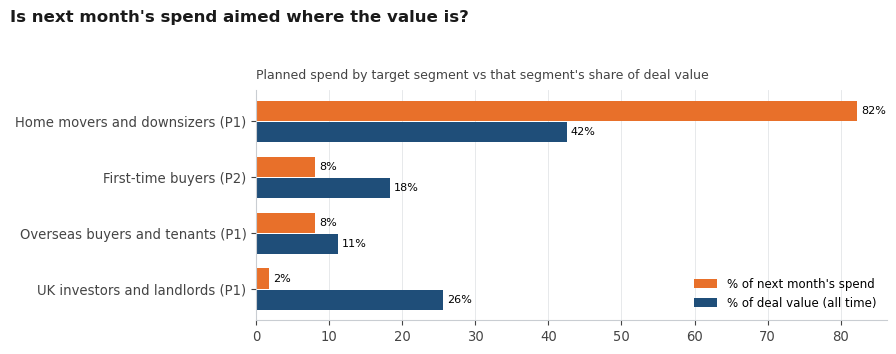

In [6]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(by_seg) + 1.5))
d = by_seg.iloc[::-1]
y = np.arange(len(d))
ax.barh(y + 0.19, d.pct_of_spend, 0.36, color=vx.ORANGE, label="% of next month's spend")
ax.barh(y - 0.19, d.pct_of_deal_value.fillna(0), 0.36, color=vx.NAVY, label="% of deal value (all time)")
for i, (a, b) in enumerate(zip(d.pct_of_spend, d.pct_of_deal_value.fillna(0))):
    ax.annotate(f"{a:.0f}%", (a, i + 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.annotate(f"{b:.0f}%", (b, i - 0.19), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y, [f"{s} ({t})" for s, t in zip(d.target_segment, d.priority_tier)])
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
p_plan = vx.finish(fig, ax, "Is next month's spend aimed where the value is?", "Planned spend by target segment vs that segment's share of deal value",
                   CH / "01_spend_vs_value.png")

## 4. The campaign test: design, A/A check and results to date

In [7]:
ts = Q("SELECT * FROM clean.test_settings").iloc[0]
wk = Q("SELECT * FROM clean.test_kpi_weekly ORDER BY week_starting, test_group")
sm = Q("SELECT * FROM clean.test_kpi_summary").iloc[0] if len(wk) else None
if len(wk):
    g = wk.groupby("test_group")[["leads", "leads_with_14_days", "viewing_within_14_days", "answered_within_1h", "leads_with_reply"]].sum()
    pt, pc = g.loc["Test", "viewing_within_14_days"] / g.loc["Test", "leads_with_14_days"], g.loc["Control", "viewing_within_14_days"] / g.loc["Control", "leads_with_14_days"]
    nt, nc = g.loc["Test", "leads_with_14_days"], g.loc["Control", "leads_with_14_days"]
    pool = (g.viewing_within_14_days.sum()) / (nt + nc)
    se = np.sqrt(pool * (1 - pool) * (1 / nt + 1 / nc))
    zst = (pt - pc) / se
    pval = 2 * (1 - stats.norm.cdf(abs(zst)))
    ci = ((pt - pc) - 1.96 * np.sqrt(pt * (1 - pt) / nt + pc * (1 - pc) / nc), (pt - pc) + 1.96 * np.sqrt(pt * (1 - pt) / nt + pc * (1 - pc) / nc))
    mde = 2.8 * np.sqrt(2 * pc * (1 - pc) / ((nt + nc) / 2))
    g1t = g.loc["Test", "answered_within_1h"] / g.loc["Test", "leads_with_reply"]
    g1c = g.loc["Control", "answered_within_1h"] / g.loc["Control", "leads_with_reply"]
    is_aa = "A/A" in str(ts.test_name)
    res = dict(test=100 * pt, control=100 * pc, uplift=100 * (pt - pc), ci=(100 * ci[0], 100 * ci[1]), p=pval, n_t=int(nt), n_c=int(nc),
               mde=100 * mde, guard_t=100 * g1t, guard_c=100 * g1c)
    verdict = ("A/A check passed: the two groups do not differ (p = {p:.2f}), so the split and the monitoring query work." if is_aa and pval >= 0.05 else
               "A/A check FAILED: the groups differ without any treatment; check the assignment before launching." if is_aa else
               "Target reached and significant." if pval < 0.05 and 100 * (pt - pc) >= float(ts.target_uplift_pts) else
               "Not (yet) a significant win at the target uplift.").format(p=pval)
    say(f"**{ts.test_name}** · target segment **{ts.target_segment}** · {ts.start_date} to {ts.end_date}  \n"
        f"Viewing within 14 days: Test **{res['test']:.1f}%** vs Control **{res['control']:.1f}%** "
        f"(uplift {res['uplift']:+.1f} pts, 95% CI {res['ci'][0]:+.1f} to {res['ci'][1]:+.1f}, p = {pval:.2f}; n = {res['n_t']:,} / {res['n_c']:,}).  \n"
        f"Guardrail (answered within 1 h): Test {res['guard_t']:.1f}% vs Control {res['guard_c']:.1f}%.  \n**{verdict}**")
else:
    res = None
    say(f"No leads in the test window for target segment **{ts.target_segment}**. If you switched to seg-v1.0, point the test at a "
        f"seg-v1.0 segment: see the UPDATE note in week3/13_crm_activation_and_test.sql STEP 4.")

**Senior 1-hour reply for P1 home movers (A/A check)** · target segment **Home movers and downsizers** · 2026-08-03 to 2026-09-13  
Viewing within 14 days: Test **51.9%** vs Control **49.9%** (uplift +2.0 pts, 95% CI -4.4 to +8.5, p = 0.53; n = 464 / 465).  
Guardrail (answered within 1 h): Test 14.5% vs Control 18.8%.  
**A/A check passed: the two groups do not differ (p = 0.53), so the split and the monitoring query work.**

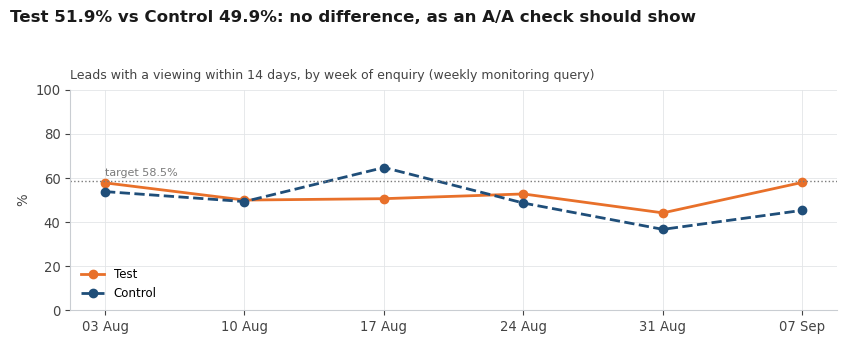

In [8]:
if res:
    w = wk.assign(rate=100 * wk.viewing_within_14_days / wk.leads_with_14_days.replace(0, np.nan)).pivot(index="week_starting", columns="test_group", values="rate")
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    ax.plot(w.index, w["Test"], color=vx.ORANGE, lw=2, marker="o", label="Test")
    ax.plot(w.index, w["Control"], color=vx.NAVY, lw=2, marker="o", ls="--", label="Control")
    ax.axhline(float(ts.baseline_pct) + float(ts.target_uplift_pts), color=vx.MUTED, lw=1, ls=":")
    ax.annotate(f"target {float(ts.baseline_pct) + float(ts.target_uplift_pts):.1f}%", (w.index[0], float(ts.baseline_pct) + float(ts.target_uplift_pts)),
                xytext=(0, 4), textcoords="offset points", fontsize=8, color=vx.MUTED)
    ax.legend(loc="lower left")
    ax.set_ylim(0, 100)
    ax.set_xticks(list(w.index), [pd.Timestamp(x).strftime("%d %b") for x in w.index])
    p_test = vx.finish(fig, ax, f"Test {res['test']:.1f}% vs Control {res['control']:.1f}%: " + ("no difference, as an A/A check should show" if is_aa and res["p"] >= .05 else f"uplift {res['uplift']:+.1f} pts"),
                       "Leads with a viewing within 14 days, by week of enquiry (weekly monitoring query)", CH / "02_test_weekly.png", ylabel="%")

## 5. Dashboard reconciliation: every Power BI number next to its SQL value

In [9]:
recon = []
for tbl, page, cols in [("clean.powerbi_check", "Overview", "measure, sql_value"),
                        ("clean.segment_check", "Overview / Segment deep dive", "*")]:
    if vx.exists(tbl):
        d = Q(f"SELECT {cols} FROM {tbl}")
        d.insert(0, "page", page)
        d.insert(1, "source", tbl)
        recon.append(d)
pages = [("Overview: KPI cards", "clean.powerbi_check"), ("Overview: segments vs value", "clean.segment_comparison (model in use)"),
         ("Segment deep dive: cards, index, channels, action", "clean.segment_profile / segment_index / segment_channels / segment_actions"),
         ("Pipeline and agents: tiers by desk", "clean.open_leads_by_tier"), ("Pipeline and agents: test KPI", "clean.test_kpi_summary / test_kpi_weekly"),
         ("Payments and lettings: late share", "clean.clean_payments (is_late_or_overdue)"), ("Data check page", "dq.dq_log, clean.powerbi_check, clean.crm_export_counts"),
         ("Monitoring", "clean.monitoring_latest")]
checklist = pd.DataFrame(pages, columns=["Dashboard page / visual", "SQL source to reconcile with"]).assign(**{"Matches after refresh? (Y/N)": "", "Checked by / date": ""})
mon = Q("SELECT * FROM clean.monitoring_latest") if vx.exists("clean.monitoring_latest") else pd.DataFrame()
with pd.ExcelWriter(OUT / "Veltrix_dashboard_reconciliation.xlsx", engine="openpyxl") as xw:
    checklist.to_excel(xw, sheet_name="checklist", index=False)
    for d in recon:
        d.to_excel(xw, sheet_name=d.source.iloc[0].split(".")[1][:31], index=False)
    counts.to_excel(xw, sheet_name="crm_export_counts", index=False)
    if len(mon):
        mon.to_excel(xw, sheet_name="monitoring_latest", index=False)
    for ws in xw.sheets.values():
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(60, max(10, max(len(str(c.value or "")) for c in col) + 2))
if len(mon):
    alerts = mon[mon.astype(str).apply(lambda r: r.str.contains("ALERT", case=False)).any(axis=1)]
    say(f"Latest monitoring run: **{len(mon)} checks, {len(alerts)} alert(s)**.")
checklist

Latest monitoring run: **16 checks, 0 alert(s)**.

,Dashboard page / visual,SQL source to reconcile with,Matches after refresh? (Y/N),Checked by / date
0,Overview: KPI cards,clean.powerbi_check,,
1,Overview: segments vs value,clean.segment_comparison (model in use),,
2,"Segment deep dive: cards, index, channels, action",clean.segment_profile / segment_index / segmen...,,
3,Pipeline and agents: tiers by desk,clean.open_leads_by_tier,,
4,Pipeline and agents: test KPI,clean.test_kpi_summary / test_kpi_weekly,,
5,Payments and lettings: late share,clean.clean_payments (is_late_or_overdue),,
6,Data check page,"dq.dq_log, clean.powerbi_check, clean.crm_expo...",,
7,Monitoring,clean.monitoring_latest,,


## 6. Activation and test report (Word)

In [10]:
r = vx.Report("Activation and test report", f"Phase 5 · Activation and testing · segmentation {MODEL}",
              f"CRM fields, routing rules, audiences, campaign plan, campaign test · generated by notebooks/07_activation_and_testing.ipynb on {TODAY}")
r.h1("Summary")
p1 = open_t.set_index("priority_tier").loc["P1"] if "P1" in set(open_t.priority_tier) else None
r.kpis([(f"{len(crm):,}", "customers with segment + tier"), (f"{len(rules)}", "routing rules"),
        (f"{int(R.drop(columns='Customers').values.sum()):,}" if len(R) else "-", "audience records, 5 channels"),
        (f"{len(plan)}", "campaigns with a target segment")])
bul = [f"**Every lead carries a segment and a priority tier** ({lead_check.with_segment_and_tier:,} of {lead_check.leads:,} leads), via its customer.",
       "**Routing:** window shoppers go to automated nurture before any agent sees them; enquiries are routed by segment to a desk and seniority with the tier's reply target."]
if p1 is not None:
    bul.append(f"**Today only {p1.pct_with_senior:.0f}% of the {int(p1.open_leads):,} open P1 leads sit with senior agents**: re-assigning them is the first job after go-live.")
if len(eng):
    wsn = eng.set_index("engagement_status").customers.get("Window shopper", 0)
    bul.append(f"**{wsn:,} window shoppers** ({100 * wsn / len(crm):.0f}% of customers) move to automated nurture, freeing agent time for serious buyers and tenants.")
if res:
    bul.append(f"**Campaign test:** {verdict}")
r.bullets(bul)
r.h1("1. CRM fields")
r.p("Fields the CRM team adds or updates. The customer file is crm_segments_<date>.csv; routing rules are in the workbook.")
r.table(fields, font=7.5, widths_cm=[3, 3.2, 2, 4.5, 3.3, 2.5])
r.h1("2. Routing rules")
r.p("Rules are checked in order; the first match wins.")
if len(rules):
    rr = rules[["rule_order", "applies_to", "priority_tier", "route_to_desk", "agent_level", "first_reply_target_min", "action"]]
    rr.columns = ["#", "Applies to", "Tier", "Desk", "Agent level", "Reply target (min)", "Action"]
    r.table(rr, font=7.5, widths_cm=[0.8, 3.5, 1, 3, 2.7, 1.8, 4.7])
r.table(tiers[["segment_name", "priority_tier", "value_per_lead_index", "value_per_closed_lead_gbp", "conversion_pct", "routed_desk"]].rename(columns={
    "segment_name": "Segment", "priority_tier": "Tier", "value_per_lead_index": "Value per lead index", "value_per_closed_lead_gbp": "£ per closed lead",
    "conversion_pct": "Conversion %", "routed_desk": "Desk"}), caption="Why each segment has its tier (100 = average lead)", font=8, widths_cm=[4.5, 1.2, 2.5, 2.8, 2.2, 3.8])
r.table(open_t.rename(columns={"priority_tier": "Tier", "open_leads": "Open leads", "with_senior": "With a senior agent", "pct_with_senior": "% with senior"}),
        caption="Open pipeline today by tier", widths_cm=[3, 4, 5, 5])
r.h1("3. Audiences per segment")
r.p("Only customers who consented to marketing. Ad platforms receive SHA-256 hashes, never raw e-mail or phone; WeChat covers residents of "
    "China, Hong Kong, Singapore and Malaysia. Confirm each platform's hash format before the first upload.")
if len(R):
    r.table(R.reset_index().rename(columns={"segment_name": "Segment"}), caption="Reachable customers per segment and channel", font=8)
if len(nurt):
    r.table(nurt.rename(columns={"nurture_track": "Nurture track", "on_list": "Consenting window shoppers"}), caption="Automated nurture list", widths_cm=[8, 6])
r.h1("4. Campaign plan")
r.p("Next month's campaigns, each with a target_segment: the segment that has brought the most deal value through that channel. "
    "Marketing can change any target; the column must not be left empty.")
cp = plan[["campaign_id", "channel", "theme", "target_segment", "priority_tier", "planned_spend_gbp"]].head(25)
cp.columns = ["Campaign", "Channel", "Theme", "Target segment", "Tier", "Spend £"]
r.table(cp, font=7.5, widths_cm=[3.3, 2.5, 3.6, 4, 1.2, 2.4], caption=f"Campaign plan (first 25 of {len(plan)}; all in Veltrix_campaign_plan.xlsx)")
r.image(p_plan, "Planned spend vs deal value by target segment")
r.h1("5. The campaign test")
r.h2("Design")
r.table(pd.DataFrame([["Test", str(ts.test_name)], ["Target segment", str(ts.target_segment)], ["Dates", f"{ts.start_date} to {ts.end_date} (6 weeks)"],
                      ["Treatment", "Senior agent, first reply within 1 hour, 7 days a week"], ["Control", "Standard handling"],
                      ["Assignment", "50/50 by a fixed hash of lead_id (a lead never changes group)"],
                      ["Primary KPI", str(ts.primary_kpi)], ["Guardrail", "Answered within 1 hour must rise in Test, or the treatment did not happen"],
                      ["Win", f"Test beats Control by at least {float(ts.target_uplift_pts):.0f} points, p < 0.05"],
                      ["Monitoring", "clean.test_kpi_weekly, refreshed every Monday (Pipeline and agents page)"]],
                     columns=["Item", "Setting"]), widths_cm=[4, 13])
if res:
    r.h2("Results to date" + (" (A/A check on past data)" if is_aa else ""))
    r.table(pd.DataFrame([["Leads with 14 days of follow-up", f"{res['n_t']:,}", f"{res['n_c']:,}"],
                          ["Viewing within 14 days", f"{res['test']:.1f}%", f"{res['control']:.1f}%"],
                          ["Answered within 1 hour (guardrail)", f"{res['guard_t']:.1f}%", f"{res['guard_c']:.1f}%"]],
                         columns=["", "Test", "Control"]), widths_cm=[8, 4, 4])
    r.p(f"Difference {res['uplift']:+.1f} points (95% CI {res['ci'][0]:+.1f} to {res['ci'][1]:+.1f}), p = {res['p']:.2f}. "
        f"With this many leads the test can detect an uplift of about {res['mde']:.0f} points (80% power, 5% significance).")
    r.callout(f"**{verdict}**")
    r.image(p_test, "Weekly monitoring query: Test vs Control")
r.p("The real test starts when its dates are set in clean.test_settings (see the note in file 13, STEP 4). Re-run this notebook after six weeks "
    "to produce the final test results.", muted=True)
r.h2("Approval (gate: test design approved before launch)")
r.table(pd.DataFrame([["Business analyst lead", "", ""], ["Head of sales", "", ""], ["Data scientist", "", ""]],
                     columns=["Role", "Name", "Date approved"]), widths_cm=[5, 7, 5])
r.h1("6. Dashboard and monitoring")
r.p("The 4-page Power BI dashboard (Overview, Segment deep dive, Pipeline and agents, Payments and lettings, plus the Data check page) reads the views above. "
    "After each refresh, every number is checked against its SQL source with Veltrix_dashboard_reconciliation.xlsx.")
r.table(checklist[["Dashboard page / visual", "SQL source to reconcile with"]], font=8, widths_cm=[6.5, 10.5])
if len(mon):
    r.p(f"Latest monitoring run: {len(mon)} checks, {len(alerts)} alert(s). Segment sizes are compared with the handover baseline; "
        "a shift above 20% raises an alert and triggers a model review.")
r.save(OUT / "Veltrix_activation_and_test_report.docx")

Saved reports\07_activation\Veltrix_activation_and_test_report.docx
